# Latent-state electoral environment and market feedback

This notebook does two things:

1. **Sample paths.** It simulates the latent-state ground truth at parameters matching the ABM and checks that it behaves as the theory says.
2. **Feedback with a whale.** It runs the CLOB market from `bettor.py` with market feedback, starting from a 50/50 market with one realistic whale, and measures how far the whale moves the *outcome* as well as the price.

It is self-contained: it imports `Bettor`, `add_whale`, `run_market_lob` and `OrderBook` from the repository and changes nothing else. Run it from the repository root.

## New RW Model

$$z_0=\Phi^{-1}(\eta_0),\qquad
z_{t+1}=z_t+\frac{\beta}{T}\,p_t+\sqrt{\frac{\lambda}{T}}\,\epsilon_t,\qquad p_t=2P_t-1,\qquad \epsilon_t\sim\mathcal N(0,1),$$

$$\eta_t=\Phi\!\left(\frac{z_t}{\sqrt{1-\lambda t/T}}\right),\qquad
S=\mathbf 1\{z_T+\nu>0\},\quad \nu\sim\mathcal N(0,1-\lambda).$$

- $\lambda\in[0,1]$ is the share of uncertainty resolved during the campaign.
- $\beta$ is the strength of feedback, measured in units of initial uncertainty. $\beta=0$ is the exogenous baseline.
- Within each period: agents observe $\eta_t$ and update their beliefs, they trade, the price $P_t$ forms (the end-of-period midquote, as in `run_market_lob`), and then $z$ is updated.
- With $\beta\neq0$, $\eta_t$ is the *fundamental* probability, i.e. the probability if market influence stopped. Agents do not anticipate their own influence.

In [1]:
import math
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figure_style as style
from bettor import Bettor, add_whale, fundamental_path, run_market_lob
from orderbook import OrderBook

style.apply()
C = style.color

## Model functions

`simulate_paths` is the vectorised electoral environment, for exogenous prices or no feedback. `run_market_feedback` is `run_market_lob` with the fundamental generated period by period from the latent state, so the price can feed back into it. The matching step in the market loop is copied from `run_market_lob` without changes. A validation cell further down checks that it reproduces `run_market_lob` exactly.

In [2]:
_erf = np.vectorize(math.erf, otypes=[float])
_STD_NORMAL = NormalDist()


def Phi(x):
    # Standard normal CDF (no scipy dependency).
    return 0.5 * (1.0 + _erf(np.asarray(x, dtype=float) / math.sqrt(2.0)))


def Phi_inv(p):
    # Standard normal quantile.
    return _STD_NORMAL.inv_cdf(p)


def remaining_sd(t, T, lam):
    # s_t = sqrt(1 - lam t / T): uncertainty left at t, with total uncertainty at t = 0 equal to 1.
    return np.sqrt(np.maximum(1.0 - lam * np.asarray(t, dtype=float) / T, 0.0))


def eta_from_z(z, t, T, lam):
    # eta_t = Phi(z_t / s_t); when s_t = 0 (lam = 1, t = T) this is 1{z_T > 0}.
    s = remaining_sd(t, T, lam)
    z = np.asarray(z, dtype=float)
    return np.where(s > 0, Phi(z / np.where(s > 0, s, 1.0)), (z > 0).astype(float))


def simulate_paths(eta0, lam, T, n_paths, rng, beta=0.0, prices=None):
    # Electoral environment with exogenous prices P_t (shape (T,) or (n_paths, T); default 0.5,
    # i.e. no feedback). Returns z and eta, each (n_paths, T + 1), and the outcomes S.
    z = np.empty((n_paths, T + 1))
    z[:, 0] = Phi_inv(eta0)
    eps = rng.standard_normal((n_paths, T))
    prices = np.full(T, 0.5) if prices is None else np.asarray(prices, dtype=float)
    prices = np.broadcast_to(prices, (n_paths, T))
    for t in range(T):
        z[:, t + 1] = (z[:, t] + beta / T * (2 * prices[:, t] - 1)
                       + math.sqrt(lam / T) * eps[:, t])
    eta = eta_from_z(z, np.arange(T + 1), T, lam)
    S = (z[:, T] + math.sqrt(1 - lam) * rng.standard_normal(n_paths) > 0).astype(int)
    return z, eta, S


def win_probability(z_T, lam):
    # Pr(S = 1 | z_T): the outcome probability once the campaign is over. Averaging this rather
    # than S gives the same expected value with much less Monte Carlo noise.
    z_T = np.asarray(z_T, dtype=float)
    return Phi(z_T / math.sqrt(1 - lam)) if lam < 1 else (z_T > 0).astype(float)


def run_market_feedback(bettors, T, eta0, lam, beta, z_rng, market_rng, tick=0.01, ttl=5,
                        max_markup=0.05, initial_price=0.5, update_first=True, eta_path=None):
    # The CLOB of bettor.run_market_lob, with the fundamental generated on the fly by the
    # latent-state model plus feedback. Order within period t (update_first=True):
    #   1. eta_t = Phi(z_t / s_t); active agents update beliefs from eta_t and the reference price
    #   2. agents trade in random order, exactly as in run_market_lob; P_t is the end-of-period mid
    #   3. z_{t+1} = z_t + (beta / T)(2 P_t - 1) + sqrt(lam / T) eps_t
    # update_first=False uses run_market_lob's order instead (trade, then update from eta_t).
    # With an exogenous eta_path, it then reproduces run_market_lob exactly (validation).
    ob = OrderBook(tick=tick)
    mkt_price = float(initial_price)
    total_cash = sum(b.budget for b in bettors)
    total_contracts = sum(b.n_contracts for b in bettors)

    z = Phi_inv(eta0) if eta_path is None else np.nan
    z_hist, eta_hist, price_hist, whale_pos = [z], [], [mkt_price], []

    for t in range(T):
        eta_t = float(eta_from_z(z, t, T, lam)) if eta_path is None else float(eta_path[t])
        eta_hist.append(eta_t)
        agents = np.asarray([i for i, b in enumerate(bettors) if b.entry_time <= t])
        if update_first:
            for i in agents:
                bettors[i].update_belief(eta_t, mkt_price)

        ob.expire(t)
        for i in agents[market_rng.permutation(len(agents))]:
            agent = bettors[i]
            ob.cancel_trader(i)
            order = agent.limit_order(ob.mid(mkt_price), ob, market_rng, max_markup)
            if order is None:
                continue
            side, price, qty = order
            if agent.worst_case_wealth(side * qty, price) < 0:
                continue
            for buyer, seller, fill_price, fill_qty in ob.submit(i, side, price, qty, t, ttl):
                bettors[buyer].n_contracts += fill_qty
                bettors[buyer].budget -= fill_qty * fill_price
                bettors[seller].n_contracts -= fill_qty
                bettors[seller].budget += fill_qty * fill_price

        assert sum(b.n_contracts for b in bettors) == total_contracts, "contracts not conserved"
        assert np.isclose(sum(b.budget for b in bettors), total_cash), "cash not conserved"
        mkt_price = ob.mid(mkt_price)                                    # P_t
        price_hist.append(mkt_price)
        whale_pos.append(sum(b.n_contracts for b in bettors if b.whale))
        if not update_first:
            for i in agents:
                bettors[i].update_belief(eta_t, mkt_price)
        if eta_path is None:
            z = z + beta / T * (2 * mkt_price - 1) + math.sqrt(lam / T) * z_rng.standard_normal()
            z_hist.append(z)

    out = {"price": np.asarray(price_hist), "eta": np.asarray(eta_hist),
           "whale_contracts": np.asarray(whale_pos)}
    if eta_path is None:
        z_hist = np.asarray(z_hist)
        out.update(z=z_hist, eta_T=float(eta_from_z(z_hist[-1], T, T, lam)),
                   p_win=float(win_probability(z_hist[-1], lam)),
                   S=int(z_hist[-1] + math.sqrt(1 - lam) * z_rng.standard_normal() > 0))
    return out

## Part 1: Sample paths

**Parameters, chosen to match the ABM.**
- $T=100$ periods, the horizon used for Figures 1–3.
- $\eta_0=0.5$, as in the ABM's `INITIAL_PRICE`.
- The old bounded walk (`fundamental_path(0.5, T, 0.05)`) is included for comparison.

**Choosing $\lambda$.** Near $\eta=\tfrac12$, the per-step volatility of $\eta$ is about $\varphi(0)\sqrt{\lambda/T}\approx0.4\sqrt{\lambda/T}$. At $T=100$:
- $\lambda=0.5$ gives about 0.028 per step.
- Matching the old walk's 0.05 per step would need $\lambda\approx1.6$, i.e. *more* uncertainty than full resolution allows.

So the old walk was far more volatile than any coherent probability process over this horizon. In a real campaign, opinion shifts during the campaign and election-day polling error are of similar size, which is why $\lambda=0.5$ is the baseline.

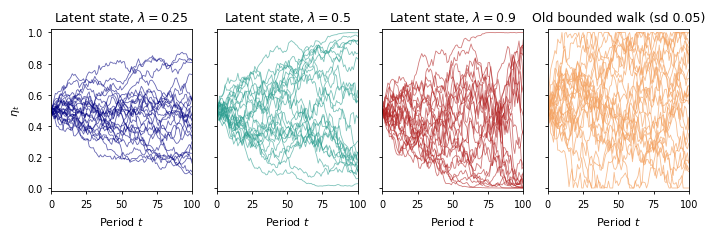

In [3]:
T = 100
ETA0 = 0.5
OLD_SD = 0.05                    # step size of the current bounded walk in the ABM
LAMBDAS = (0.25, 0.5, 0.9)
N_SHOW = 25                      # sample paths per panel

rng = np.random.default_rng(7)
fig, axes = plt.subplots(1, 4, figsize=(style.PAGE_WIDTH, 2.3), sharey=True,
                         constrained_layout=True)
lam_colors = C(["navy", "teal", "ruby"])
for ax, lam, col in zip(axes, LAMBDAS, lam_colors):
    _, eta, S = simulate_paths(ETA0, lam, T, N_SHOW, rng)
    for k in range(N_SHOW):
        ax.plot(eta[k], color=col, lw=0.6, alpha=0.6)
    ax.set(title=rf"Latent state, $\lambda={lam}$", xlabel="Period $t$", xlim=(0, T))
old = np.array([fundamental_path(ETA0, T, OLD_SD, rng) for _ in range(N_SHOW)])
for k in range(N_SHOW):
    axes[-1].plot(old[k], color=C("orange"), lw=0.6, alpha=0.7)
axes[-1].set(title="Old bounded walk (sd 0.05)", xlabel="Period $t$", xlim=(0, T))
axes[0].set(ylabel=r"$\eta_t$", ylim=(-0.02, 1.02))
plt.show()

**Checks.** These are computed over 20,000 paths each, starting from $\eta_0=0.7$ so that any bias from the bounds would show. For a genuine probability process:
- $\mathbb E[\eta_t]$ stays at $\eta_0$ (martingale), and $\Pr(S=1)=\eta_0$.
- The ground truth's own Brier score, $\mathbb E[\eta_t(1-\eta_t)]$, falls over time.

The old walk has no outcome rule. To give it a "Brier score", we treat its terminal value as the probability of the outcome.

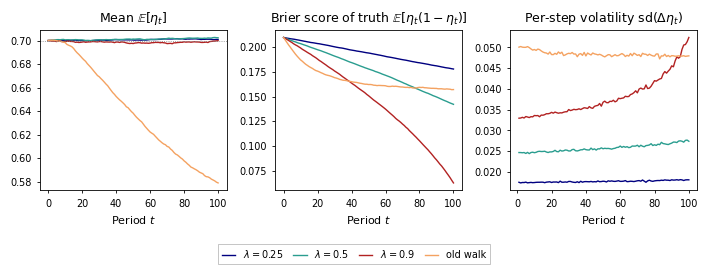

,process,E[eta_T],Pr(S=1),share |eta_T - 1/2| > 0.4
0,"latent, lambda=0.25",0.701,0.701,0.123
1,"latent, lambda=0.5",0.702,0.702,0.319
2,"latent, lambda=0.9",0.700,0.700,0.713
3,old bounded walk,0.579,NaN,0.246


In [4]:
N_MC = 20_000
ETA0_CHECK = 0.7
rng = np.random.default_rng(11)
times = np.arange(T + 1)

fig, axes = plt.subplots(1, 3, figsize=(style.PAGE_WIDTH, 2.6), layout="constrained")
rows = []
for lam, col in zip(LAMBDAS, lam_colors):
    _, eta, S = simulate_paths(ETA0_CHECK, lam, T, N_MC, rng)
    axes[0].plot(times, eta.mean(0), color=col, label=rf"$\lambda={lam}$")
    axes[1].plot(times, (eta * (1 - eta)).mean(0), color=col)
    axes[2].plot(times[1:], np.diff(eta, axis=1).std(0), color=col)
    rows.append({"process": f"latent, lambda={lam}", "E[eta_T]": eta[:, -1].mean(),
                 "Pr(S=1)": S.mean(), "share |eta_T - 1/2| > 0.4": np.mean(abs(eta[:, -1] - .5) > .4)})
old = np.array([fundamental_path(ETA0_CHECK, T, OLD_SD, rng) for _ in range(N_MC)])
axes[0].plot(times, old.mean(0), color=C("orange"), label="old walk")
axes[1].plot(times, (old * (1 - old)).mean(0), color=C("orange"))
axes[2].plot(times[1:], np.diff(old, axis=1).std(0), color=C("orange"))
rows.append({"process": "old bounded walk", "E[eta_T]": old[:, -1].mean(), "Pr(S=1)": np.nan,
             "share |eta_T - 1/2| > 0.4": np.mean(abs(old[:, -1] - .5) > .4)})

axes[0].axhline(ETA0_CHECK, color="grey", lw=0.6, ls=":")
axes[0].set(title=r"Mean $\mathbb{E}[\eta_t]$", xlabel="Period $t$")
axes[1].set(title=r"Brier score of truth $\mathbb{E}[\eta_t(1-\eta_t)]$", xlabel="Period $t$")
axes[2].set(title=r"Per-step volatility sd$(\Delta\eta_t)$", xlabel="Period $t$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
plt.show()
pd.DataFrame(rows).round(3)

## Part 2: Feedback with a single whale in a 50/50 market

**Design.**
- 100 ordinary bettors, built as in `experiments/whale_convergence_experiment.py`: budgets U(100, 1000) scaled by $1-\rho$, initial valuations N(0.5, 0.05), other traits drawn by `Bettor`, no herding.
- One whale: capital share $\rho=0.3$, valuation 0.7, risk aversion 0.5, trading from $t=0$. These are the paper's default whale settings.
- $\eta_0=0.5$ and $T=100$.
- $\lambda=0$: no campaign shocks, so $\eta$ moves *only* through feedback. This isolates the mechanism.
- $\lambda=0.5$: the realistic baseline.
- $\beta\in\{-1,0,1,2\}$. $\beta=1$ means consistently one-sided sentiment shifts the state by one initial standard deviation over the campaign.

**Pairing.** Each seed is run with and without the whale, using identical ordinary traders, identical belief signals and identical shocks to $z$. The shocks are also shared across values of $\beta$. The **whale effect** is the paired difference in the final outcome probability, $\Pr(S=1\mid z_T)$. Pairing matters because level feedback reinforces whoever is the current favourite even when there is no whale.

**First, validation.** With $\beta=0$, an exogenous path and `run_market_lob`'s update order, `run_market_feedback` should reproduce `run_market_lob` exactly.

In [5]:
N_BETTORS = 100
WHALE_SHARE = 0.3
WHALE_VALUATION = 0.7
WHALE_RISK_AV = 0.5


def make_population(seed, whale):
    # Ordinary bettors as in whale_convergence_experiment.make_population (budgets scaled by
    # 1 - WHALE_SHARE in both arms, so the ordinary traders are identical with and without the whale).
    rng = np.random.default_rng(seed)
    np.random.seed(seed)
    population = [Bettor(budget=rng.uniform(100, 1000) * (1 - WHALE_SHARE),
                         market_valuation=np.clip(rng.normal(0.5, 0.05), 0.01, 0.99))
                  for _ in range(N_BETTORS)]
    if whale:
        add_whale(population, WHALE_SHARE, WHALE_VALUATION, risk_av=WHALE_RISK_AV)
    np.random.seed(10_000 + seed)        # identical belief signals in both arms
    return population


seed = 3
path = fundamental_path(0.5, T, 0.05, np.random.default_rng(seed))
ref = run_market_lob(make_population(seed, True), T, path, 0.5, rng=np.random.default_rng(seed))
new = run_market_feedback(make_population(seed, True), T, 0.5, 0.5, 0.0, None,
                          np.random.default_rng(seed), update_first=False, eta_path=path)
print("max |price difference| vs run_market_lob:",
      np.max(np.abs(np.asarray(ref["price_history"]) - new["price"])))

max |price difference| vs run_market_lob: 0.0


**A benchmark with no market.** Before running the ABM, suppose the whale simply holds the price at the theoretical level $P=\eta_0+\rho\Delta=0.5+0.3\times0.2=0.56$ throughout. Then sentiment is $p=0.12$, and the state shifts by $D_T=0.12\,\beta$. The cell below computes the resulting change in $\Pr(S=1)$ relative to a price held at 0.5. This is the effect you would expect *without* the market adjusting, a reference line for the ABM results.

In [6]:
BETAS = (-1.0, 0.0, 1.0, 2.0)
MARKET_LAMBDAS = (0.0, 0.5)
P_WHALE = 0.5 + WHALE_SHARE * (WHALE_VALUATION - 0.5)

benchmark = {}
for lam in MARKET_LAMBDAS:
    for beta in BETAS:
        z_w, *_ = simulate_paths(ETA0, lam, T, 20_000, np.random.default_rng(1), beta, P_WHALE)
        z_c, *_ = simulate_paths(ETA0, lam, T, 20_000, np.random.default_rng(1), beta, 0.5)
        benchmark[lam, beta] = np.mean(win_probability(z_w[:, -1], lam)
                                       - win_probability(z_c[:, -1], lam))
pd.Series(benchmark, name="fixed-price benchmark: change in Pr(S=1)").unstack(0).round(3)

,0.0,0.5
-1.0,-0.048,-0.048
0.0,0.000,0.000
1.0,0.048,0.048
2.0,0.095,0.094


**The ABM experiment.** This takes 2 values of λ × 4 values of β × 2 arms × `N_RUNS` market runs, at about 0.5 s each. With `N_RUNS = 60` that is roughly 8 minutes. Increase `N_RUNS` for tighter confidence intervals.

In [7]:
N_RUNS = 60

records, trajectories = [], {}
for lam in MARKET_LAMBDAS:
    for beta in BETAS:
        for seed in range(N_RUNS):
            for whale in (False, True):
                out = run_market_feedback(make_population(seed, whale), T, ETA0, lam, beta,
                                          z_rng=np.random.default_rng(50_000 + seed),
                                          market_rng=np.random.default_rng(seed))
                P = out["price"][1:]
                records.append({"lambda": lam, "beta": beta, "seed": seed, "whale": whale,
                                "p_win": out["p_win"], "eta_T": out["eta_T"], "S": out["S"],
                                "mean_price": P.mean(), "mean_sentiment": (2 * P - 1).mean(),
                                "D_T": beta * (2 * P - 1).mean(),
                                "mean_error": np.mean(P - out["eta"])})
                trajectories[lam, beta, seed, whale] = out
runs = pd.DataFrame(records)
print(f"{len(runs)} runs")

960 runs


In [8]:
# Paired whale effects: with whale minus without, seed by seed.
paired = runs.pivot_table(index=["lambda", "beta", "seed"], columns="whale",
                          values=["p_win", "mean_price", "D_T", "mean_error"])
effect = pd.DataFrame({k: paired[k, True] - paired[k, False]
                       for k in ["p_win", "mean_price", "D_T", "mean_error"]})


def mean_ci(x):
    return pd.Series({"mean": x.mean(), "ci95": 1.96 * x.std(ddof=1) / np.sqrt(len(x))})


summary = effect.groupby(["lambda", "beta"]).agg(["mean", lambda x: 1.96 * x.std(ddof=1) / np.sqrt(len(x))])
summary.columns = [f"{a} ({'mean' if b == 'mean' else '±95%'})" for a, b in summary.columns]
summary["fixed-price benchmark, p_win"] = [benchmark[i] for i in summary.index]
summary.round(3)

p_win (mean)  p_win (±95%)  mean_price (mean)  mean_price (±95%)  \
lambda beta                                                                     
0.0    -1.0        -0.028         0.001              0.036              0.001   
        0.0         0.000         0.000              0.048              0.001   
        1.0         0.054         0.002              0.067              0.002   
        2.0         0.147         0.005              0.095              0.003   
0.5    -1.0        -0.024         0.005              0.025              0.005   
        0.0         0.000         0.000              0.030              0.009   
        1.0         0.039         0.011              0.038              0.015   
        2.0         0.097         0.029              0.047              0.024   

             D_T (mean)  D_T (±95%)  mean_error (mean)  mean_error (±95%)  \
lambda beta                                                                 
0.0    -1.0      -0.071       0.002              0.051              0.002   
        0.0       0.000       0.000              0.048              0.001   
        1.0       0.135       0.004              0.044              0.001   
        2.0       0.378       0.013              0.036              0.001   
0.5    -1.0      -0.049       0.010              0.039              0.007   
        0.0       0.000       0.000              0.030              0.009   
        1.0       0.077       0.030              0.019              0.012   
        2.0       0.189       0.095              0.002              0.016   

             fixed-price benchmark, p_win  
lambda beta                                
0.0    -1.0                        -0.048  
        0.0                         0.000  
        1.0                         0.048  
        2.0                         0.095  
0.5    -1.0                        -0.048  
        0.0                         0.000  
        1.0                         0.048  
        2.0                         0.094

NameError: name 'trajectories' is not defined

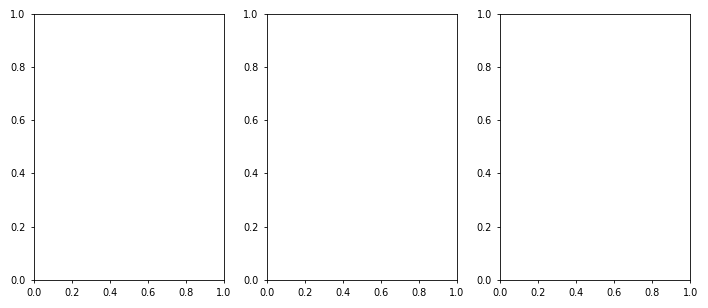

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(style.PAGE_WIDTH, 3.0), layout="constrained")

# A: one paired run at the realistic baseline, beta = 1
lam_ex, beta_ex, seed_ex = 0.5, 1.0, 0
ax = axes[0]
for whale, col, lab in ((False, C("steel"), "no whale"), (True, C("ruby"), "whale")):
    out = trajectories[lam_ex, beta_ex, seed_ex, whale]
    ax.plot(out["eta"], color=col, lw=1.0, ls="--")
    ax.plot(out["price"][1:], color=col, lw=0.8, label=lab)
ax.set(title=rf"Example run ($\lambda={lam_ex}$, $\beta={beta_ex:g}$)", xlabel="Period $t$",
       ylabel=r"Price (solid), $\eta_t$ (dashed)", xlim=(0, T))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)

# B: whale effect on the outcome probability against beta
ax = axes[1]
for lam, col in zip(MARKET_LAMBDAS, C(["indigo", "teal"])):
    e = effect.loc[lam, "p_win"].groupby("beta").apply(mean_ci).unstack()
    ax.errorbar(e.index, e["mean"], yerr=e["ci95"], color=col, marker="o", ms=3, capsize=2,
                label=rf"ABM, $\lambda={lam:g}$")
    ax.plot(BETAS, [benchmark[lam, b] for b in BETAS], color=col, ls=":", lw=0.9,
            label=rf"fixed price, $\lambda={lam:g}$")
ax.axhline(0, color="grey", lw=0.5)
ax.set(title=r"Whale effect on $\Pr(S=1)$", xlabel=r"Feedback strength $\beta$",
       ylabel="With whale − without")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)

# C: lock-in without a whale: spread of final outcome probabilities by beta (lambda = 0.5)
ax = axes[2]
ctrl = runs[(runs["lambda"] == 0.5) & (~runs["whale"])]
ax.boxplot([ctrl.loc[ctrl["beta"] == b, "p_win"] for b in BETAS],
           tick_labels=[f"{b:g}" for b in BETAS], widths=0.5, showfliers=False)
ax.set(title=r"No whale: final $\Pr(S=1)$ ($\lambda=0.5$)", xlabel=r"$\beta$",
       ylabel=r"$\Pr(S=1\mid z_T)$")
plt.show()

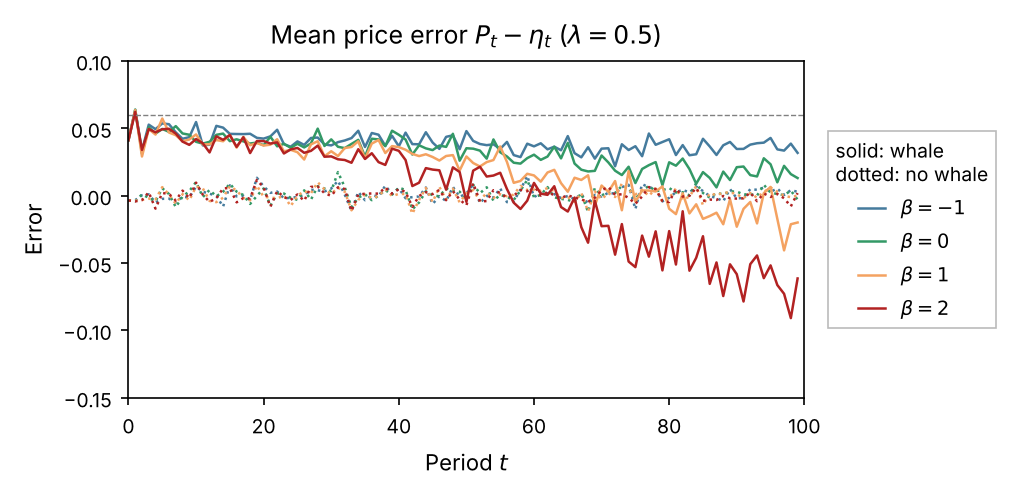

In [10]:
# Mean price error relative to the fundamental, over time (lambda = 0.5)
fig, ax = plt.subplots(figsize=(5.0, 2.4), layout="constrained")
for beta, col in zip(BETAS, C(["steel", "green", "orange", "ruby"])):
    for whale, ls in ((False, ":"), (True, "-")):
        err = np.mean([trajectories[0.5, beta, s, whale]["price"][1:]
                       - trajectories[0.5, beta, s, whale]["eta"] for s in range(N_RUNS)], axis=0)
        ax.plot(err, color=col, ls=ls, lw=0.9, label=rf"$\beta={beta:g}$" if whale else None)
ax.axhline(WHALE_SHARE * (WHALE_VALUATION - 0.5), color="grey", lw=0.5, ls="--")
ax.set(title=r"Mean price error $P_t-\eta_t$ ($\lambda=0.5$)", xlabel="Period $t$",
       ylabel="Error", xlim=(0, T))
ax.legend(title="solid: whale\ndotted: no whale", loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylim(-0.15, 0.1)
plt.show()

## Notes and interpretation

**Part 1: the ground truth.**
- The latent-state process behaves like a genuine probability. Starting from $\eta_0=0.7$, $\mathbb E[\eta_t]$ stays at 0.70 for every $\lambda$, and the simulated outcome frequency $\Pr(S=1)$ is 0.70.
- The old bounded walk does not. Clipping at the bounds pulls its mean from 0.70 down to about 0.58 by $t=100$, so it is not a martingale. Its per-step volatility is a constant 0.05 whatever the time left.
- In the latent model, volatility comes out of the model: about 0.018, 0.025 and 0.033 per step for $\lambda=0.25$, 0.5 and 0.9. At high $\lambda$, close races become more volatile as the election approaches. The ground truth's Brier score falls faster when more uncertainty is resolved during the campaign.
- Even at $\lambda=0.9$, the latent model is less volatile than the old walk for most of the campaign. **$\lambda=0.5$ is a reasonable baseline** for $T=100$.

**Part 2: feedback with one whale (ρ = 0.3, valuation 0.7, 60 paired seeds).**
- *Validation.* With $\beta=0$ and an exogenous path, the feedback market reproduces `run_market_lob` exactly.
- *Feedback only ($\lambda=0$).* The whale holds the price about 5 points above $\eta$. Its effect on $\Pr(S=1)$ is close to the fixed-price benchmark at $\beta=1$ (0.054 vs 0.048). At $\beta=2$ it is about 1.5 times the benchmark (0.147 vs 0.095). With negative feedback it is damped (−0.028 vs −0.048). Positive feedback compounds: the whale moves $\eta$ towards its side, the price follows $\eta$ up, and sentiment, and hence feedback, grows further. Negative feedback moves $\eta$ against the price and partly cancels the whale's push.
- *Realistic baseline ($\lambda=0.5$).* The effects are similar in size to the benchmark (0.039 at $\beta=1$, 0.097 at $\beta=2$, −0.024 at $\beta=-1$), with wider intervals. Campaign shocks often push $\eta$ above the whale's valuation, and from there the whale sells rather than buys, which limits its influence. With $\beta=2$, the mean price error with a whale turns *negative* late in the campaign: the fundamental overtakes the price the whale was pushing.
- *Feedback without a whale.* Level feedback spreads out the final outcome probabilities as $\beta$ increases, because whoever leads gets pushed further ahead. This is the lock-in behaviour of the Reality Game, and it is why the whale effect has to be measured by paired comparison.

**Caveats.**
- The intervals come from 60 paired seeds. Raise `N_RUNS` for publication figures.
- Bettors have no herding ($h=0$, the `Bettor` default). Herding should raise the whale's pass-through and so its effect on the outcome. Adding it is the natural next experiment.
- $\beta$ is not calibrated, so read the results as a function of feedback strength.
- Agents update on $\eta_t$ before trading in period $t$, as in the manuscript. `run_market_lob` updates after trading, so the two differ by one period.